# Biologically invalid transitions in the CRF

Reads the outputs of `crf_invalid_transitions.py` (run once per model):
1. the learned CRF transition scores, grouped by their initialization in training (invalid: -10; valid but infrequent:
   the tuned `transition_weight`; frequent self-transitions: 0);
2. how often a transition initialized as invalid occurs in the decoded label sequences of the 300 bp typical-error
   test set (212 genomes using translation table 11).

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display

sys.path.insert(0, "../../benchmark/eval")   # plot_config.py
from plot_config import FONT_SIZES, MODEL_COLORS

plt.rcParams.update(FONT_SIZES)
RESULTS_DIR = "/tmp/nrt204/FragmentPredictor/data/processed_data/model_behavior/crf_transitions"
MODEL_DATA = "/tmp/nrt204/FragmentPredictor/data/processed_data/model_data/shared_crf"
DATA_DIR = "with_errors_5e-06i_0.004s_300bp"
SAVE_OUTPUTS = True
MODELS = {"N": ("DeepCDS N", "model_without_errors", "deep_cds_no_errors"),
          "S": ("DeepCDS S", "model_with_substitution_errors", "deep_cds_substitution"),
          "SI": ("DeepCDS S+I", "model_with_errors", "deep_cds_errors")}
GROUPS = {"invalid": "Invalid", "valid_infrequent": "Valid,\ninfrequent", "frequent": "Frequent\nself-transition"}

## 1. Learned transition scores by initialization group

count    min    25%   50%   75%   max  initial value
model init_group                                                             
N     frequent             4.0  -0.03  -0.01 -0.00  0.01  0.05           0.00
      invalid            965.0 -18.55 -10.54 -8.98 -8.32 -8.03         -10.00
      valid_infrequent   120.0  -5.15  -3.08 -2.26 -1.70 -1.27          -1.88
S     frequent             4.0  -0.10  -0.05 -0.04 -0.03  0.01           0.00
      invalid            965.0 -18.37 -10.97 -9.20 -8.21 -7.86         -10.00
      valid_infrequent   120.0  -7.42  -4.55 -3.40 -2.59 -2.24          -3.28
SI    frequent             4.0  -0.14  -0.08 -0.04 -0.01  0.02           0.00
      invalid           4134.0 -15.71  -9.07 -8.57 -8.51 -8.49         -10.00
      valid_infrequent   623.0  -8.70  -4.67 -4.02 -3.42 -1.26          -3.42

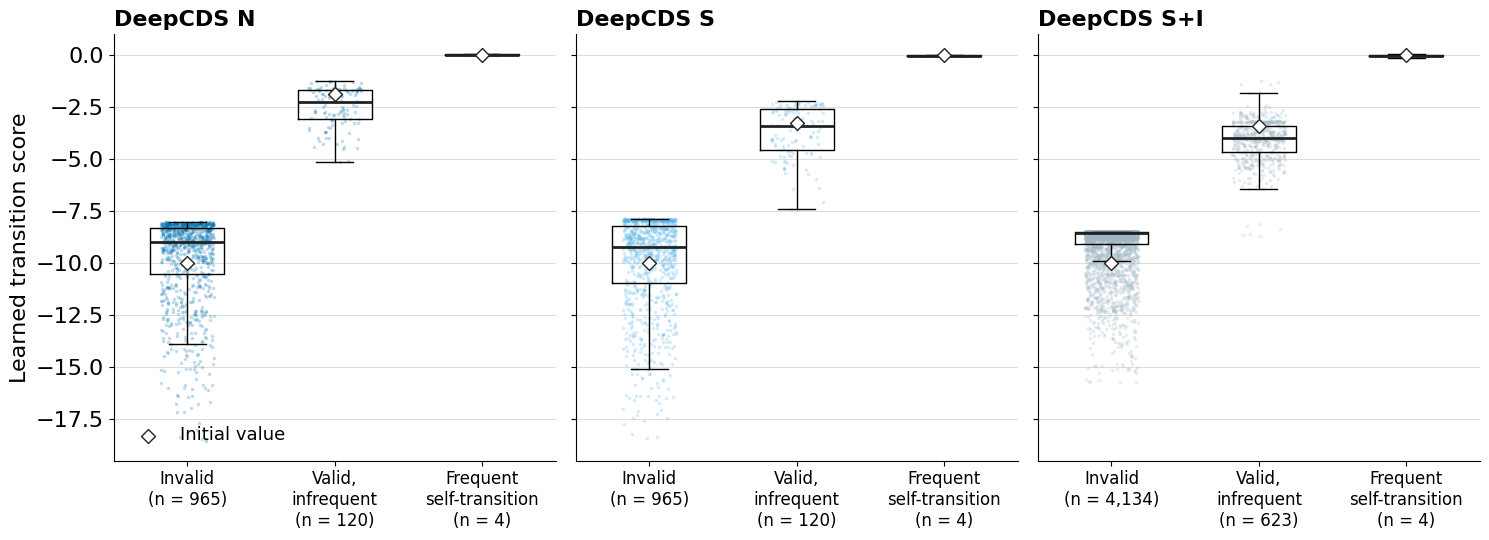

In [ ]:
learned = pd.concat([pd.read_csv(f"{RESULTS_DIR}/learned_transitions_{m}.tsv", sep="\t").assign(model=m) for m in MODELS])
init_w = {m: yaml.safe_load(open(f"{MODEL_DATA}/{d}/hyperparameter_configs/full_model_hyperparameters.yaml"))
             ["hyperparameters"]["transition_weight"] for m, (_, d, _) in MODELS.items()}
init = {"invalid": lambda m: -10.0, "valid_infrequent": lambda m: init_w[m], "frequent": lambda m: 0.0}

summary = learned.groupby(["model", "init_group"])["learned_score"].describe()[["count", "min", "25%", "50%", "75%", "max"]]
summary["initial value"] = [init[g](m) for m, g in summary.index]
display(summary.round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 5.5), sharey=True)
rng = np.random.default_rng(42)
for ax, (m, (name, _, color_key)) in zip(axes, MODELS.items()):
    data = [learned.loc[(learned["model"] == m) & (learned["init_group"] == g), "learned_score"] for g in GROUPS]
    ax.boxplot(data, widths=0.5, showfliers=False, medianprops=dict(color="#222222", linewidth=2), zorder=2)
    for k, (g, v) in enumerate(zip(GROUPS, data), start=1):
        ax.scatter(k + rng.uniform(-0.18, 0.18, len(v)), v, s=10, alpha=0.9, color=MODEL_COLORS[color_key],
                   edgecolor="#555555", linewidth=0.2, zorder=1)
        ax.scatter(k, init[g](m), marker="D", s=50, color="white", edgecolor="#222222", zorder=3,
                   label="Initial value" if k == 1 else None)
    ax.set_xticks(range(1, len(GROUPS) + 1), [f"{l}\n(n = {len(v):,})" for l, v in zip(GROUPS.values(), data)], fontsize=12)
    ax.set_title(name, loc="left", fontweight="bold")
    ax.yaxis.grid(True, color="#dddddd"); ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
axes[0].set_ylabel("Learned transition score")
axes[-1].legend(frameon=False, loc="lower right")
fig.tight_layout()
plt.show()
if SAVE_OUTPUTS:
    os.makedirs(f"{RESULTS_DIR}/figures", exist_ok=True)
    for ext, kw in (("pdf", {}), ("png", {"dpi": 600})):
        fig.savefig(f"{RESULTS_DIR}/figures/crf_learned_transition_scores.{ext}", bbox_inches="tight", **kw)

## 2. Invalid transitions in the decoded label sequences

Per model: test sequences whose decoded label sequence contains at least one transition initialized as invalid, and
the number of such transitions among all decoded transitions (consecutive codon positions).

In [3]:
rows = []
for m, (name, _, _) in MODELS.items():
    path = f"{RESULTS_DIR}/decoded_transitions_{m}_{DATA_DIR}.tsv"
    if not os.path.exists(path):
        print(f"{name}: not computed yet"); continue
    d = pd.read_csv(path, sep="\t")
    rows.append({"model": name, "genomes": len(d), "sequences": d["reads"].sum(),
                 "sequences with an invalid transition": d["reads_with_invalid"].sum(),
                 "% of sequences": 100 * d["reads_with_invalid"].sum() / d["reads"].sum(),
                 "transitions": d["transitions"].sum(), "invalid transitions": d["invalid_transitions"].sum()})
decoded = pd.DataFrame(rows, columns=["model", "genomes", "sequences", "sequences with an invalid transition",
                                    "% of sequences", "transitions", "invalid transitions"]).set_index("model")
display(decoded)
for m, (name, _, _) in MODELS.items():
    path = f"{RESULTS_DIR}/invalid_transition_pairs_{m}_{DATA_DIR}.tsv"
    if os.path.exists(path) and os.path.getsize(path) > 0:
        pairs = pd.read_csv(path, sep="\t")
        if len(pairs):
            print(f"{name}: invalid transitions by label pair (shared labels = per-frame labels RF0, RF1, RF2)")
            display(pairs.head(10))
if SAVE_OUTPUTS:
    decoded.to_csv(f"{RESULTS_DIR}/decoded_invalid_transitions_summary.csv")

DeepCDS N: not computed yet
DeepCDS S: not computed yet
DeepCDS S+I: not computed yet


,genomes,sequences,sequences with an invalid transition,% of sequences,transitions,invalid transitions
model,,,,,,
